<a href="https://colab.research.google.com/github/saurabhsen848/Deep-Learning/blob/main/Project11_MNIST_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 11: Handwritten Digit Classification Using CNN
**Dataset:** MNIST (70,000 grayscale 28x28 images of digits 0-9) | **Framework:** TensorFlow / Keras

**Goal:** Build and train a basic Convolutional Neural Network, then evaluate it with accuracy, a confusion matrix, a classification report and sample predictions.

## Setup

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## Task 1: Load and preprocess MNIST
MNIST comes pre-split into 60,000 training and 10,000 test images.

In [9]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
print("Train:", x_train.shape, y_train.shape)
print("Test: ", x_test.shape, y_test.shape)
print("Pixel range:", x_train.min(), "to", x_train.max())

Train: (60000, 28, 28) (60000,)
Test:  (10000, 28, 28) (10000,)
Pixel range: 0 to 255


### Look at the data

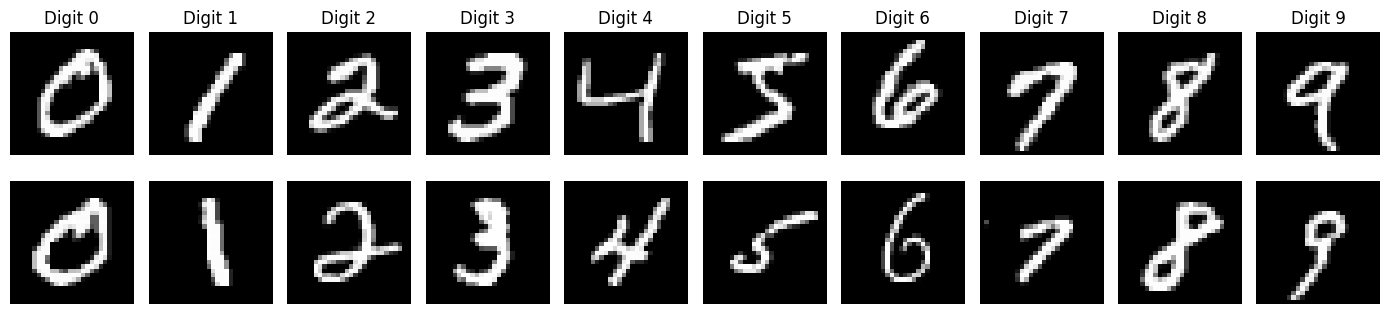

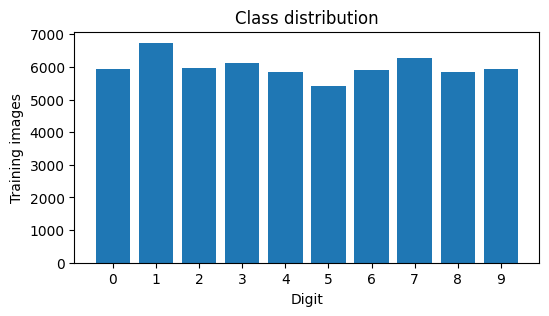

In [10]:
fig, axes = plt.subplots(2, 10, figsize=(14, 3.5))
for d in range(10):
    idx = np.where(y_train == d)[0][:2]
    for r, i in enumerate(idx):
        axes[r, d].imshow(x_train[i], cmap="gray"); axes[r, d].axis("off")
        if r == 0: axes[r, d].set_title(f"Digit {d}")
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 3))
plt.bar(*np.unique(y_train, return_counts=True))
plt.xticks(range(10)); plt.xlabel("Digit"); plt.ylabel("Training images"); plt.title("Class distribution")
plt.show()

### Preprocess
1. **Normalize** pixel values from 0-255 to 0-1 so training is stable.
2. **Reshape** to `(28, 28, 1)`, because Conv2D layers expect a channel dimension.
3. Keep labels as integers 0-9 (we use `sparse_categorical_crossentropy`, so one-hot encoding is not needed).

In [11]:
x_train = (x_train.astype("float32") / 255.0)[..., np.newaxis]
x_test  = (x_test.astype("float32") / 255.0)[..., np.newaxis]
print("Train:", x_train.shape, "| Test:", x_test.shape)
print("Pixel range:", x_train.min(), "to", x_train.max())

Train: (60000, 28, 28, 1) | Test: (10000, 28, 28, 1)
Pixel range: 0.0 to 1.0


## Task 2: Build and train the CNN
| Layer | Purpose |
|---|---|
| Conv2D(32, 3x3, ReLU) | Learns small local patterns (edges, strokes) |
| MaxPooling2D(2x2) | Halves the spatial size, keeps the strongest responses |
| Conv2D(64, 3x3, ReLU) | Combines edges into larger shapes (loops, curves) |
| MaxPooling2D(2x2) | Further downsampling |
| Flatten | Turns feature maps into a vector |
| Dropout(0.5) | Regularization to reduce overfitting |
| Dense(10, softmax) | Probability for each digit |

In [12]:
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax"),
])
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │        16,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

### Train
10% of the training data is held out as a validation set so we can watch for overfitting without touching the test set. Early stopping restores the best weights.

In [13]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
history = model.fit(x_train, y_train,
                    epochs=15, batch_size=128,
                    validation_split=0.1,
                    callbacks=[early_stop], verbose=2)

Epoch 1/15
422/422 - 46s - 109ms/step - accuracy: 0.8896 - loss: 0.3710 - val_accuracy: 0.9782 - val_loss: 0.0816
Epoch 2/15
422/422 - 40s - 95ms/step - accuracy: 0.9658 - loss: 0.1147 - val_accuracy: 0.9848 - val_loss: 0.0563
Epoch 3/15
422/422 - 41s - 97ms/step - accuracy: 0.9739 - loss: 0.0854 - val_accuracy: 0.9872 - val_loss: 0.0479
Epoch 4/15
422/422 - 40s - 95ms/step - accuracy: 0.9788 - loss: 0.0708 - val_accuracy: 0.9893 - val_loss: 0.0412
Epoch 5/15
422/422 - 41s - 97ms/step - accuracy: 0.9808 - loss: 0.0632 - val_accuracy: 0.9887 - val_loss: 0.0395
Epoch 6/15
422/422 - 40s - 95ms/step - accuracy: 0.9823 - loss: 0.0563 - val_accuracy: 0.9898 - val_loss: 0.0378
Epoch 7/15
422/422 - 40s - 95ms/step - accuracy: 0.9841 - loss: 0.0512 - val_accuracy: 0.9907 - val_loss: 0.0350
Epoch 8/15
422/422 - 41s - 97ms/step - accuracy: 0.9842 - loss: 0.0493 - val_accuracy: 0.9908 - val_loss: 0.0323
Epoch 9/15
422/422 - 40s - 95ms/step - accuracy: 0.9861 - loss: 0.0447 - val_accuracy: 0.9917 -

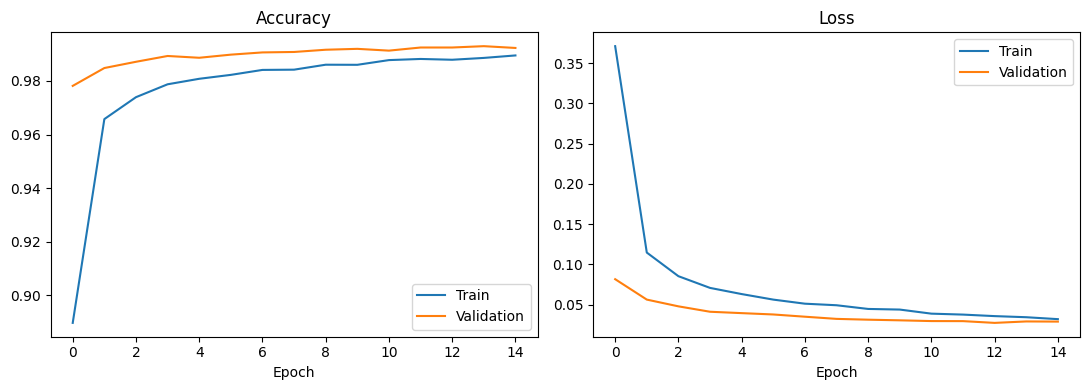

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history["accuracy"], label="Train"); ax[0].plot(history.history["val_accuracy"], label="Validation")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history.history["loss"], label="Train"); ax[1].plot(history.history["val_loss"], label="Validation")
ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

## Task 3: Evaluate on the test set

In [15]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f}   Test loss: {test_loss:.4f}")

probs = model.predict(x_test, verbose=0)
y_pred = probs.argmax(axis=1)

Test accuracy: 0.9911   Test loss: 0.0266


### Confusion matrix
Rows are the true digit, columns are the predicted digit. Off-diagonal cells are mistakes.

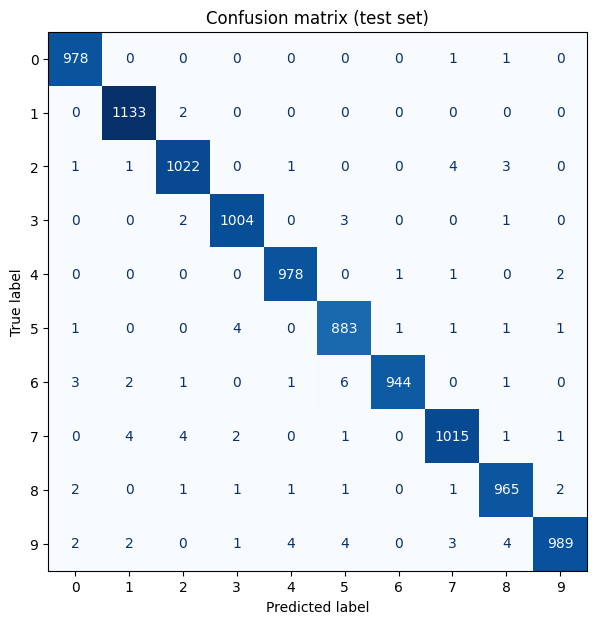

Most common mistakes (true -> predicted):
  6 -> 5: 6 images
  9 -> 8: 4 images
  9 -> 5: 4 images
  9 -> 4: 4 images
  7 -> 2: 4 images
  7 -> 1: 4 images
  5 -> 3: 4 images
  2 -> 7: 4 images


In [16]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Confusion matrix (test set)"); plt.show()

# Most frequently confused digit pairs
off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted(((off[i, j], i, j) for i in range(10) for j in range(10) if off[i, j] > 0), reverse=True)[:8]
print("Most common mistakes (true -> predicted):")
for n, t, p in pairs:
    print(f"  {t} -> {p}: {n} images")

### Classification report (precision, recall, F1 per digit)

In [17]:
print(classification_report(y_test, y_pred, digits=4))

              precision    recall  f1-score   support

           0     0.9909    0.9980    0.9944       980
           1     0.9921    0.9982    0.9952      1135
           2     0.9903    0.9903    0.9903      1032
           3     0.9921    0.9941    0.9931      1010
           4     0.9929    0.9959    0.9944       982
           5     0.9833    0.9899    0.9866       892
           6     0.9979    0.9854    0.9916       958
           7     0.9893    0.9874    0.9883      1028
           8     0.9877    0.9908    0.9892       974
           9     0.9940    0.9802    0.9870      1009

    accuracy                         0.9911     10000
   macro avg     0.9910    0.9910    0.9910     10000
weighted avg     0.9911    0.9911    0.9911     10000



### Sample predictions

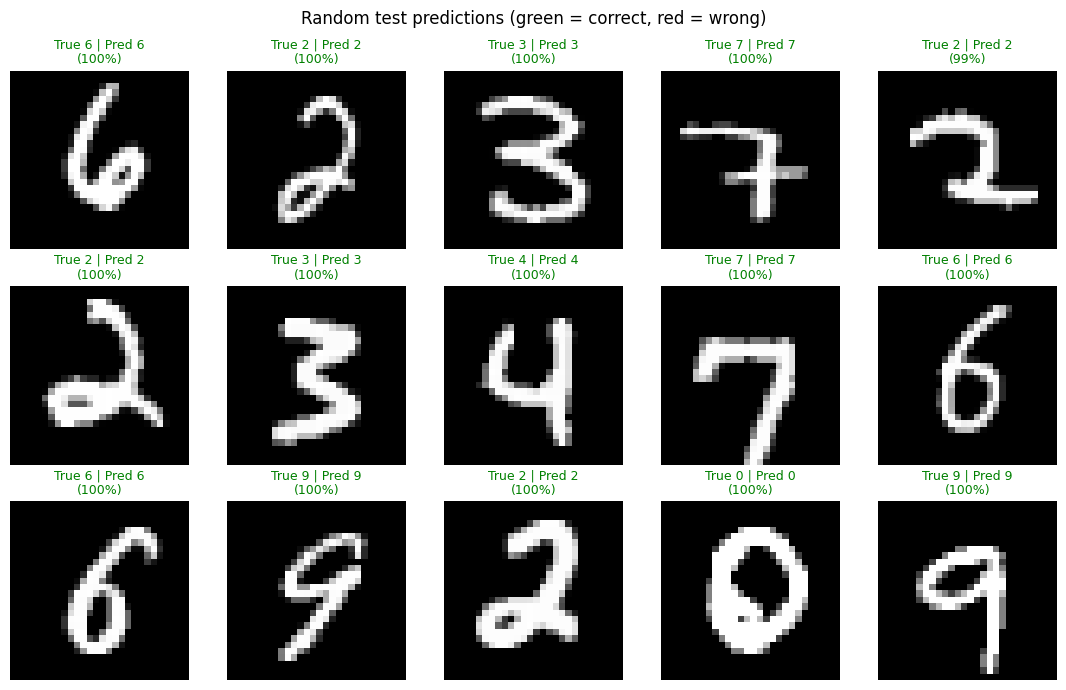

In [18]:
rng = np.random.RandomState(SEED)
idx = rng.choice(len(x_test), 15, replace=False)
fig, axes = plt.subplots(3, 5, figsize=(11, 7))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(x_test[i].squeeze(), cmap="gray"); ax.axis("off")
    ok = y_pred[i] == y_test[i]
    ax.set_title(f"True {y_test[i]} | Pred {y_pred[i]}\n({probs[i].max():.0%})", color="green" if ok else "red", fontsize=9)
plt.suptitle("Random test predictions (green = correct, red = wrong)"); plt.tight_layout(); plt.show()

### Misclassified examples

89 of 10000 test images misclassified


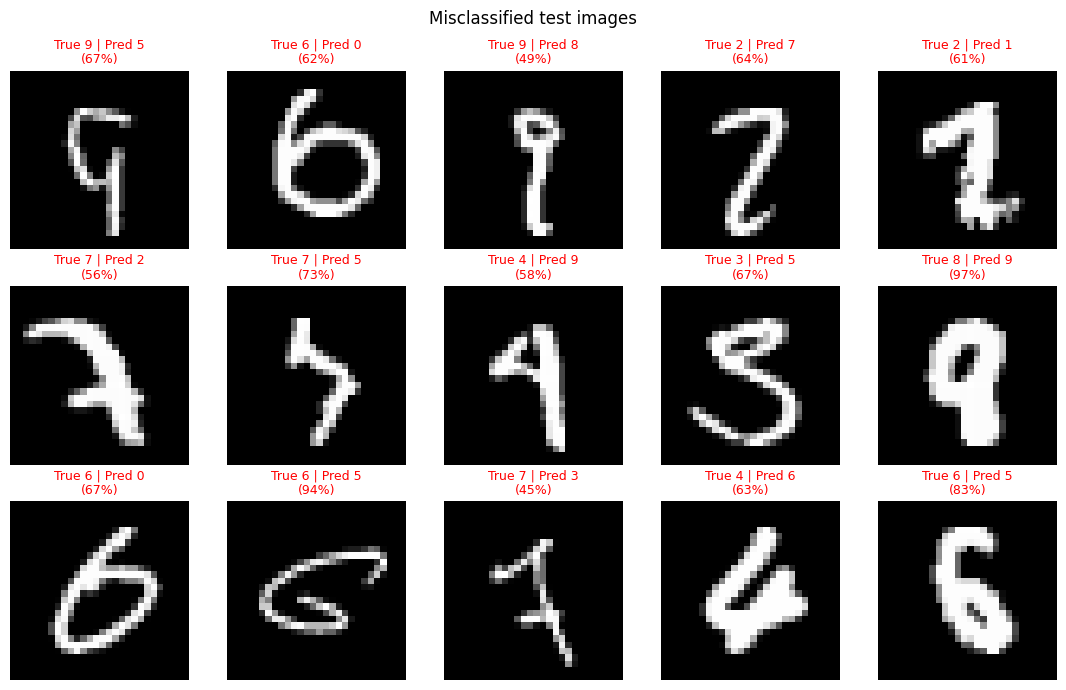

In [19]:
wrong = np.where(y_pred != y_test)[0]
print(f"{len(wrong)} of {len(y_test)} test images misclassified")
show = wrong[:15]
fig, axes = plt.subplots(3, 5, figsize=(11, 7))
for ax, i in zip(axes.ravel(), show):
    ax.imshow(x_test[i].squeeze(), cmap="gray"); ax.axis("off")
    ax.set_title(f"True {y_test[i]} | Pred {y_pred[i]}\n({probs[i].max():.0%})", color="red", fontsize=9)
plt.suptitle("Misclassified test images"); plt.tight_layout(); plt.show()

In [20]:
model.save("mnist_cnn.keras")
print("Model saved to mnist_cnn.keras")

Model saved to mnist_cnn.keras
